# HealthConnect Rwanda — Week 7: Model Testing, Error Analysis & Refinement
**AnalystLab Africa · Experience Lab · Week 7 · Data Science track**

Continues directly from Week 6 (admission-prediction classifier, 5,000 appointment encounters). This notebook does **not** repeat the Week 6 analysis:
it *tests* the Week 6 candidate model, investigates its errors, refines it on evidence, re-tests it and records the results.

**Structure** — A. Week 6 → Week 7 transition & test plan · B. Testing the candidate · C. Error analysis · D. Segment and robustness tests ·
E. Refinement and re-test · F. Cross-track test (Data Science → ML Engineering) · G. Conclusions.

**Important context.** The Week 7 brief describes a missed-appointment (no-show) classifier on `HealthConnect_Appointment_Data.csv`. That file is not part of the
project data this internship line has used since Week 4 (the 27 HealthConnect hospital files), and the data contain **no attendance/no-show field**.
As instructed ("do not select a new dataset"), Week 7 tests the Week 6 candidate classifier — **hospital admission** — and states clearly (section G) what this means for the
missed-appointment objective.

In [1]:
import warnings, os, json, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, train_test_split, cross_val_predict, cross_validate)
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve, confusion_matrix,
                             precision_score, recall_score, f1_score, matthews_corrcoef, balanced_accuracy_score)
from sklearn.inspection import permutation_importance
import joblib, textwrap
warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
import admission_risk_scorer as ars

DATA = "../outputs/data/HC_Integrated_Encounters_5000.csv"   # exported by Week 6 script 06 (no direct identifiers)
OUT = "outputs/"; FIGDIR = OUT + "figures/"; TAB = OUT + "tables/"; MOD = OUT + "models/"
for d_ in (FIGDIR, TAB, MOD): os.makedirs(d_, exist_ok=True)
SEED = 42; rng = np.random.default_rng(SEED)
R, FIGS, DQ = {}, {}, []          # headline numbers, figure captions (DQ unused, kept for the notebook runner)
TESTS = []                        # the testing record (one row per test)
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID, SURF = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
mpl.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11})

def save_fig(fig, name, interp, title):
    wrapped = "\n".join(textwrap.wrap("Interpretation: " + interp, 150))
    fig.text(0.01, -0.02, wrapped, ha="left", va="top", fontsize=8.5, color="#333")
    fig.savefig(FIGDIR + name + ".png", dpi=150, bbox_inches="tight"); FIGS[name] = dict(title=title, interp=interp)

def record(tid, scenario, expected, actual, passed, issue="", action="", retest="", track="Data Science", evidence=""):
    TESTS.append(dict(ID=tid, Scenario=scenario, Expected=expected, Actual=actual, Result="PASS" if passed else "FAIL", Issue=issue, Action=action, Retest=retest,
                      Collaborating_Track=track, Evidence=evidence))

def boot_ci(y, p, fn=roc_auc_score, n=1000, seed=SEED):
    r = np.random.default_rng(seed); out = []
    for _ in range(n):
        ix = r.integers(0, len(y), len(y))
        if len(np.unique(y[ix])) == 2: out.append(fn(y[ix], p[ix]))
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

## A. Week 6 → Week 7 transition and test plan
| # | Item | Answer |
|---|---|---|
| 1 | Main Week 6 output | Healthcare predictive-analytics package: cleaned/integrated data, 36 charts, 15 hypothesis tests, forecasts, admission & satisfaction models, clustering, reports, 8-script GitHub pipeline |
| 2 | Most important component | The **candidate classification model**: logistic regression predicting hospital admission from booking-time information (CV AUC 0.514, hold-out AUC 0.529) |
| 3 | Main issue / limitation / dependency | Week 6 found **no predictive signal** (permutation p = 0.32); the integrated data have inconsistent keys and no attendance field; model was never tested beyond one split, one threshold and no segment/robustness checks |
| 4 | Component requiring testing | The candidate model and its scoring interface |
| 5 | Relevant tracks | Data Science (owner) · ML Engineering (input/output contract, pipeline) · Data Analytics (which findings should drive features) · Project Management (issue log, readiness) |
| 6 | What I intend to test | Stability, metrics at deployable thresholds, calibration, errors (FP/FN), segments, overfitting, feature validity, whether the *test method itself* can detect signal, and the scoring interface |
| 7 | What I expect to improve/validate | Validate whether the model is fit for use; refine where evidence supports it; harden the interface for ML Engineering; decide what Week 8 needs |

### Pre-registered acceptance criteria
Criteria were fixed **before** testing so that the verdict cannot be tuned to the result. The model is *suitable for patient-level use* only if **all** hold on untouched data:

In [2]:
CRITERIA = pd.DataFrame([
    ["C1 Discrimination", "Hold-out ROC-AUC ≥ 0.65", "A model must rank admitted patients clearly above others"],
    ["C2 Significance", "Lower 95% bootstrap bound of hold-out AUC > 0.50", "Skill must be distinguishable from chance"],
    ["C3 Precision value", "PR-AUC ≥ 1.5 × prevalence", "Flagged patients must be materially enriched for admission"],
    ["C4 Stability", "AUC > 0.5 in ≥ 90% of 30 random splits, and in the time-based split", "Result must not depend on one lucky split"],
    ["C5 Calibration", "Calibration slope between 0.8 and 1.2", "Predicted risks must mean what they say"],
    ["C6 Beats baseline", "Paired CV AUC gain over the naive baseline with 95% CI excluding 0", "A model that cannot beat 'predict the average' has no value"],
], columns=["Criterion", "Rule", "Why"])
CRITERIA

,Criterion,Rule,Why
0,C1 Discrimination,Hold-out ROC-AUC ≥ 0.65,A model must rank admitted patients clearly above others
1,C2 Significance,Lower 95% bootstrap bound of hold-out AUC > 0.50,Skill must be distinguishable from chance
2,C3 Precision value,PR-AUC ≥ 1.5 × prevalence,Flagged patients must be materially enriched for admission
3,C4 Stability,"AUC > 0.5 in ≥ 90% of 30 random splits, and in the time-based split",Result must not depend on one lucky split
4,C5 Calibration,Calibration slope between 0.8 and 1.2,Predicted risks must mean what they say
5,C6 Beats baseline,Paired CV AUC gain over the naive baseline with 95% CI excluding 0,A model that cannot beat 'predict the average' has no value


In [3]:
# keep_default_na=False: the literal "None" in ChronicCondition is a valid category (no chronic disease), not a missing value
E = pd.read_csv(DATA, parse_dates=["Date"], keep_default_na=False, na_values=[""])
E["LabAbnormalNum"] = E.LabAbnormalNum.fillna(0); E["Medication"] = E.Medication.fillna("None"); E["Month_"] = E.MonthNum
NUM = ["Age", "BMI", "RiskScore", "DoctorYearsExp", "PatientVisits", "Month_", "ChronicFlag"]
CAT = ["Gender", "MaritalStatus", "Education", "Occupation", "ProvinceName", "BloodGroup", "ChronicCondition", "VisitType", "DepartmentName", "FacilityID", "DayOfWeek"]
FEATS = NUM + CAT
assert set(FEATS) == set(ars.REQUIRED), "model features must equal the scoring contract"
y = E.Admitted.values; X = E[FEATS].copy(); X["FacilityID"] = X.FacilityID.astype(str)
prev = y.mean()
print(f"Encounters: {len(E):,} | admitted: {y.sum()} ({prev:.1%}) | features: {len(NUM)} numeric + {len(CAT)} categorical | date range {E.Date.min().date()} – {E.Date.max().date()}")
print("Missing values in model features:", int(X.isna().sum().sum()))
print("Attendance / no-show column present:", any("show" in c.lower() or "attend" in c.lower() or "missed" in c.lower() for c in E.columns))

def make_pipe(est, num=NUM, cat=CAT):
    return Pipeline([("p", ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), cat)])), ("m", est)])
def cand(): return make_pipe(LogisticRegression(C=.1, max_iter=2000))           # the Week 6 candidate, unchanged
def baseline(): return make_pipe(DummyClassifier(strategy="prior"))

# development / hold-out split: identical to Week 6; the hold-out stays untouched until the final evaluation in section E
Xdev, Xho, ydev, yho = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
print(f"Development set {len(Xdev):,} (positives {ydev.sum()}) | untouched hold-out {len(Xho):,} (positives {yho.sum()})")

Encounters: 5,000 | admitted: 586 (11.7%) | features: 7 numeric + 11 categorical | date range 2026-01-01 – 2026-12-28
Missing values in model features: 0
Attendance / no-show column present: False
Development set 4,000 (positives 469) | untouched hold-out 1,000 (positives 117)


## B. Testing the candidate model
### B1. Reproducibility of the Week 6 result
*Expected:* re-running the candidate with the Week 6 protocol reproduces CV AUC 0.514 and hold-out AUC 0.529 (±0.002).

In [4]:
cvA = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
def cv_scores(mk, Xd=X, yd=y, cv=cvA, **kw):
    return cross_validate(mk(), Xd, yd, cv=cv, scoring={"auc": "roc_auc", "ap": "average_precision", "brier": "neg_brier_score"}, n_jobs=1, **kw)
cr = cv_scores(cand)
auc_cv, ap_cv, brier_cv = cr["test_auc"].mean(), cr["test_ap"].mean(), -cr["test_brier"].mean()
m0 = cand().fit(Xdev, ydev); p_ho0 = m0.predict_proba(Xho)[:, 1]; auc_ho0 = roc_auc_score(yho, p_ho0)
print(f"Candidate: repeated 5x3 CV AUC = {auc_cv:.4f} (sd {cr['test_auc'].std():.4f}) | PR-AUC {ap_cv:.4f} | Brier {brier_cv:.4f} (baseline {prev*(1-prev):.4f}) | hold-out AUC {auc_ho0:.4f}")
ok = abs(auc_cv - 0.5143) < .002 and abs(auc_ho0 - 0.5294) < .002
R["repro"] = dict(cv_auc=float(auc_cv), ho_auc=float(auc_ho0)); print("Reproduces Week 6:", ok)
record("T01", "Reproduce Week 6 candidate (CV and hold-out)", "CV AUC 0.514 and hold-out AUC 0.529 (±0.002)", f"CV AUC {auc_cv:.3f}; hold-out AUC {auc_ho0:.3f}", ok,
       evidence="notebook B1")

Candidate: repeated 5x3 CV AUC = 0.5143 (sd 0.0243) | PR-AUC 0.1291 | Brier 0.1044 (baseline 0.1035) | hold-out AUC 0.5294
Reproduces Week 6: True


### B2. Stability: 30 random splits and a time-based split
A model that is only good on one split is not reliable. Time-based testing (train Jan–Sep, test Oct–Dec) mimics deployment, where the model scores *future* appointments.

30 random 80/20 splits: AUC mean 0.495, sd 0.021, range 0.461–0.549, share > 0.5: 40%
Time-based split (train Jan–Sep n=3,765, test Oct–Dec n=1,235): AUC 0.480 (95% CI 0.433–0.528)


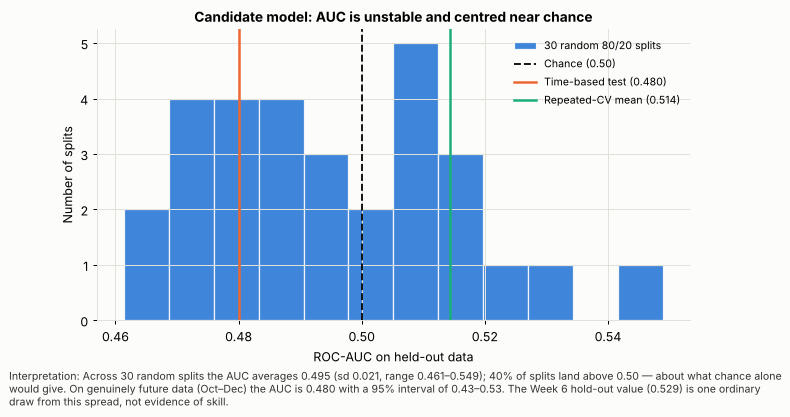

In [5]:
aucs30 = []
for s in range(30):
    a, b, ya, yb = train_test_split(X, y, test_size=.2, stratify=y, random_state=1000 + s)
    aucs30.append(roc_auc_score(yb, cand().fit(a, ya).predict_proba(b)[:, 1]))
aucs30 = np.array(aucs30)
tr_m = (E.Date.dt.month <= 9).values
mt = cand().fit(X[tr_m], y[tr_m]); pt = mt.predict_proba(X[~tr_m])[:, 1]; auc_time = roc_auc_score(y[~tr_m], pt); ci_time = boot_ci(y[~tr_m], pt)
R["stability"] = dict(mean=float(aucs30.mean()), sd=float(aucs30.std()), lo=float(np.percentile(aucs30, 2.5)), hi=float(np.percentile(aucs30, 97.5)), share_above_half=float((aucs30 > .5).mean()),
                     time_auc=float(auc_time), time_ci=ci_time, time_n=int((~tr_m).sum()), time_pos=int(y[~tr_m].sum()))
print(f"30 random 80/20 splits: AUC mean {aucs30.mean():.3f}, sd {aucs30.std():.3f}, range {aucs30.min():.3f}–{aucs30.max():.3f}, share > 0.5: {(aucs30 > .5).mean():.0%}")
print(f"Time-based split (train Jan–Sep n={tr_m.sum():,}, test Oct–Dec n={(~tr_m).sum():,}): AUC {auc_time:.3f} (95% CI {ci_time[0]:.3f}–{ci_time[1]:.3f})")
record("T02", "Stability across 30 random splits", "AUC > 0.5 in ≥ 90% of splits (C4)", f"{(aucs30 > .5).mean():.0%} above 0.5; mean {aucs30.mean():.3f} (range {aucs30.min():.3f}–{aucs30.max():.3f})", (aucs30 > .5).mean() >= .9, "Skill is not consistently above chance" if (aucs30 > .5).mean() < .9 else "", evidence="Fig. w01")
record("T03", "Time-based split (train Jan–Sep, test Oct–Dec)", "AUC > 0.5 with CI above 0.5 (C4, C2)", f"AUC {auc_time:.3f} (95% CI {ci_time[0]:.3f}–{ci_time[1]:.3f})", ci_time[0] > .5, "CI includes 0.5: no demonstrable skill on future data" if ci_time[0] <= .5 else "", evidence="Fig. w01")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(aucs30, bins=12, color=C[0], edgecolor=SURF, alpha=.9, label="30 random 80/20 splits")
ax.axvline(.5, color=INK, ls="--", lw=1.5, label="Chance (0.50)"); ax.axvline(auc_time, color=C[1], lw=2, label=f"Time-based test ({auc_time:.3f})"); ax.axvline(auc_cv, color=C[2], lw=2, label=f"Repeated-CV mean ({auc_cv:.3f})")
ax.set_xlabel("ROC-AUC on held-out data"); ax.set_ylabel("Number of splits"); ax.set_title("Candidate model: AUC is unstable and centred near chance"); ax.legend(frameon=False, fontsize=8.5)
save_fig(fig, "w01_stability", f"Across 30 random splits the AUC averages {aucs30.mean():.3f} (sd {aucs30.std():.3f}, range {aucs30.min():.3f}–{aucs30.max():.3f}); {(aucs30 > .5).mean():.0%} of splits land above 0.50 — about what chance alone would give. On genuinely future data (Oct–Dec) the AUC is {auc_time:.3f} with a 95% interval of {ci_time[0]:.2f}–{ci_time[1]:.2f}. The Week 6 hold-out value ({auc_ho0:.3f}) is one ordinary draw from this spread, not evidence of skill.", "Stability of the candidate model")
plt.show()

### B3. Classification metrics at deployable thresholds
Probability thresholds are chosen **on the development set only** (out-of-fold predictions) and then applied once to the hold-out. Three operating rules are compared with trivial baselines:
the F1-optimal threshold, a fixed 0.5 threshold, and a *capacity rule* — flag the highest-scoring 20% (what a clinic with limited outreach capacity would do).

In [6]:
oof_dev = cross_val_predict(cand(), Xdev, ydev, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
grid = np.linspace(.02, .6, 117); f1s = [f1_score(ydev, oof_dev >= t) for t in grid]; t_f1 = float(grid[int(np.argmax(f1s))])
t_cap = float(np.quantile(oof_dev, .8))
def metrics(yt, pr_, thr, label):
    yh = (pr_ >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(yt, yh, labels=[0, 1]).ravel()
    return dict(Rule=label, Threshold=round(float(thr), 3), Flagged=int(yh.sum()), TP=int(tp), FP=int(fp), FN=int(fn), TN=int(tn),
                Precision=tp / max(tp + fp, 1), Recall=tp / max(tp + fn, 1), Specificity=tn / max(tn + fp, 1), F1=f1_score(yt, yh, zero_division=0),
                Balanced_Acc=balanced_accuracy_score(yt, yh), MCC=matthews_corrcoef(yt, yh) if yh.std() > 0 else 0.0)
rows = [metrics(yho, p_ho0, t_f1, "Model, F1-optimal threshold"), metrics(yho, p_ho0, .5, "Model, threshold 0.5"), metrics(yho, p_ho0, t_cap, "Model, flag top 20% (capacity rule)"),
        metrics(yho, np.ones(len(yho)), .5, "Baseline: flag everyone"), metrics(yho, np.zeros(len(yho)), .5, "Baseline: flag no one")]
rr = np.random.default_rng(SEED).random(len(yho)); rows.append(metrics(yho, rr, np.quantile(rr, .8), "Baseline: random 20%"))
M1 = pd.DataFrame(rows); M1.to_csv(TAB + "t_metrics_candidate_holdout.csv", index=False)
pd.options.display.float_format = "{:,.3f}".format
R["metrics_candidate"] = M1.round(4).to_dict("records")
M1

,Rule,Threshold,Flagged,TP,FP,FN,TN,Precision,Recall,Specificity,F1,Balanced_Acc,MCC
0,"Model, F1-optimal threshold",0.060,985,115,870,2,13,0.117,0.983,0.015,0.209,0.499,-0.006
1,"Model, threshold 0.5",0.500,0,0,0,117,883,0.000,0.000,1.000,0.000,0.500,0.000
2,"Model, flag top 20% (capacity rule)",0.146,180,30,150,87,733,0.167,0.256,0.830,0.202,0.543,0.072
3,Baseline: flag everyone,0.500,1000,117,883,0,0,0.117,1.000,0.000,0.209,0.500,0.000
4,Baseline: flag no one,0.500,0,0,0,117,883,0.000,0.000,1.000,0.000,0.500,0.000
5,Baseline: random 20%,0.798,200,31,169,86,714,0.155,0.265,0.809,0.196,0.537,0.059


Top-20% rule: precision 0.167 vs prevalence 0.117 -> lift 1.42x (precision 95% CI 0.112–0.221); random 20% gives 0.155
F1-optimal threshold 0.060 flags 985 of 1000 patients; threshold 0.5 flags 0


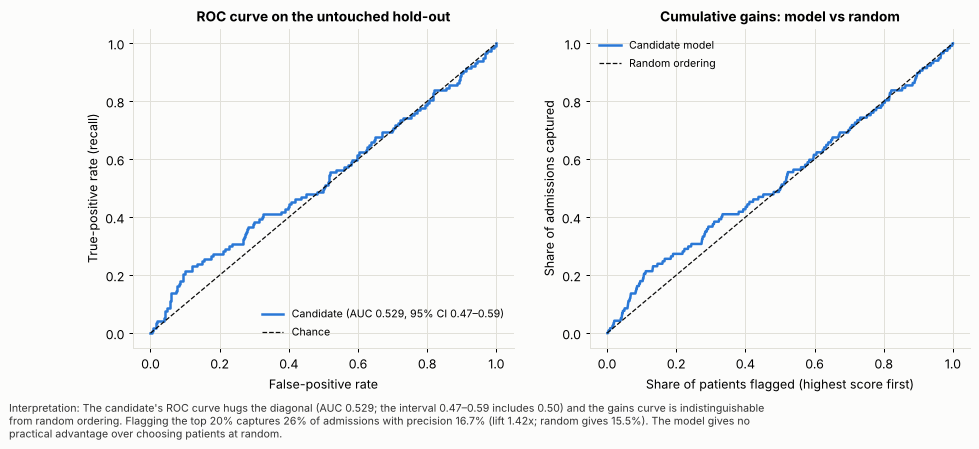

In [7]:
cap = M1[M1.Rule.str.contains("capacity")].iloc[0]; rnd = M1[M1.Rule.str.contains("random")].iloc[0]
lift = cap.Precision / yho.mean()
ci_p = boot_ci(yho, (p_ho0 >= t_cap).astype(float), fn=lambda a, b: precision_score(a, b, zero_division=0))
print(f"Top-20% rule: precision {cap.Precision:.3f} vs prevalence {yho.mean():.3f} -> lift {lift:.2f}x (precision 95% CI {ci_p[0]:.3f}–{ci_p[1]:.3f}); random 20% gives {rnd.Precision:.3f}")
print(f"F1-optimal threshold {t_f1:.3f} flags {int(M1.iloc[0].Flagged)} of {len(yho)} patients; threshold 0.5 flags {int(M1.iloc[1].Flagged)}")
R["capacity_rule"] = dict(precision=float(cap.Precision), recall=float(cap.Recall), lift=float(lift), p_lo=ci_p[0], p_hi=ci_p[1], random_precision=float(rnd.Precision), t_f1=t_f1, flagged_f1=int(M1.iloc[0].Flagged), flagged_05=int(M1.iloc[1].Flagged))
record("T04", "Metrics at deployable thresholds on untouched hold-out", "Top-20% rule has lift ≥ 1.5 over prevalence (C3)", f"Lift {lift:.2f}x (precision {cap.Precision:.3f} vs prevalence {yho.mean():.3f}); 0.5 threshold flags {int(M1.iloc[1].Flagged)} patients; F1-optimal threshold flags {int(M1.iloc[0].Flagged)} of {len(yho)}",
       lift >= 1.5, "At 0.5 the model never flags anyone; the F1-optimal threshold flags nearly everyone — the model has no useful operating point" if lift < 1.5 else "", evidence="table t_metrics_candidate_holdout.csv; Fig. w02")

# ROC + lift figure
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
fpr, tpr, _ = roc_curve(yho, p_ho0); lo_, hi_ = boot_ci(yho, p_ho0)
ax[0].plot(fpr, tpr, color=C[0], lw=2, label=f"Candidate (AUC {auc_ho0:.3f}, 95% CI {lo_:.2f}–{hi_:.2f})"); ax[0].plot([0, 1], [0, 1], color=INK, ls="--", lw=1, label="Chance")
ax[0].set_xlabel("False-positive rate"); ax[0].set_ylabel("True-positive rate (recall)"); ax[0].set_title("ROC curve on the untouched hold-out"); ax[0].legend(frameon=False, fontsize=8.5, loc="lower right")
order = np.argsort(-p_ho0); cum = np.cumsum(yho[order]); share = np.arange(1, len(yho) + 1) / len(yho)
ax[1].plot(share, cum / yho.sum(), color=C[0], lw=2, label="Candidate model"); ax[1].plot([0, 1], [0, 1], color=INK, ls="--", lw=1, label="Random ordering")
ax[1].set_xlabel("Share of patients flagged (highest score first)"); ax[1].set_ylabel("Share of admissions captured"); ax[1].set_title("Cumulative gains: model vs random"); ax[1].legend(frameon=False, fontsize=8.5)
save_fig(fig, "w02_roc_gains", f"The candidate's ROC curve hugs the diagonal (AUC {auc_ho0:.3f}; the interval {lo_:.2f}–{hi_:.2f} includes 0.50) and the gains curve is indistinguishable from random ordering. Flagging the top 20% captures {cap.Recall:.0%} of admissions with precision {cap.Precision:.1%} (lift {lift:.2f}x; random gives {rnd.Precision:.1%}). The model gives no practical advantage over choosing patients at random.", "ROC and cumulative-gains curves, hold-out set")
plt.show()

### B4. Calibration
Even a weak ranker can be useful if its probabilities are honest. We check calibration on out-of-fold predictions over all 5,000 encounters (no patient is scored by a model that saw it).

Calibration slope 0.18 (95% CI -0.06–0.41; ideal 1.0) | intercept -1.65 | Brier 0.1043 vs baseline 0.1035 | predicted range 0.033–0.349


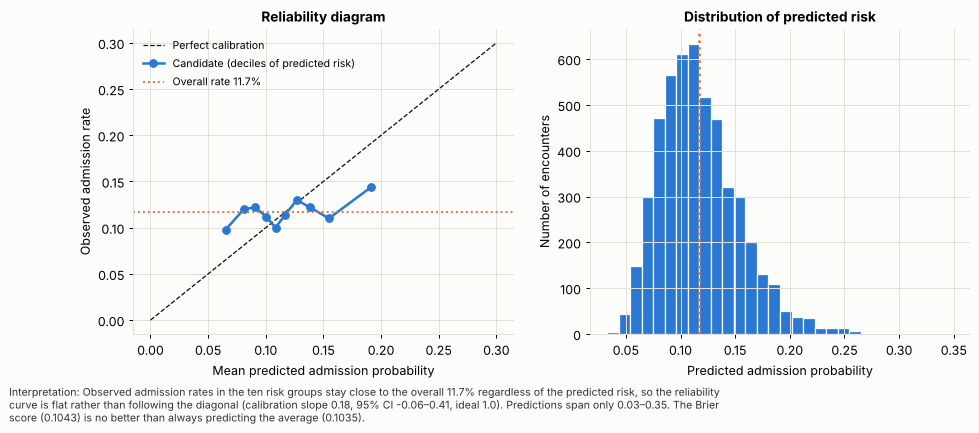

In [8]:
oof = cross_val_predict(cand(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
lg = np.log(np.clip(oof, 1e-6, 1 - 1e-6) / (1 - np.clip(oof, 1e-6, 1 - 1e-6)))
cal = LogisticRegression(C=1e6, max_iter=1000).fit(lg.reshape(-1, 1), y); slope, intercept = float(cal.coef_[0][0]), float(cal.intercept_[0])
# bootstrap CI for the slope
bs = []
for _ in range(300):
    ix = rng.integers(0, len(y), len(y)); bs.append(LogisticRegression(C=1e6, max_iter=1000).fit(lg[ix].reshape(-1, 1), y[ix]).coef_[0][0])
slope_ci = (float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5)))
brier = brier_score_loss(y, oof); brier_base = prev * (1 - prev)
bins = pd.qcut(oof, 10, duplicates="drop"); CAL = pd.DataFrame({"p": oof, "y": y, "bin": bins}).groupby("bin", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size")).reset_index(drop=True)
R["calibration"] = dict(slope=slope, intercept=intercept, slope_ci=slope_ci, brier=float(brier), brier_base=float(brier_base), pred_min=float(oof.min()), pred_max=float(oof.max()))
print(f"Calibration slope {slope:.2f} (95% CI {slope_ci[0]:.2f}–{slope_ci[1]:.2f}; ideal 1.0) | intercept {intercept:.2f} | Brier {brier:.4f} vs baseline {brier_base:.4f} | predicted range {oof.min():.3f}–{oof.max():.3f}")
record("T05", "Calibration (out-of-fold, all encounters)", "Calibration slope within 0.8–1.2 (C5) and Brier below baseline", f"Slope {slope:.2f} (95% CI {slope_ci[0]:.2f}–{slope_ci[1]:.2f}); Brier {brier:.4f} vs baseline {brier_base:.4f}",
       0.8 <= slope <= 1.2 and brier < brier_base, "Predicted risks are not informative about actual risk (slope far below 1; Brier no better than baseline)" if not (0.8 <= slope <= 1.2 and brier < brier_base) else "", evidence="Fig. w03")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].plot([0, .3], [0, .3], color=INK, ls="--", lw=1, label="Perfect calibration"); ax[0].plot(CAL.pred, CAL.obs, "o-", color=C[0], lw=2, label="Candidate (deciles of predicted risk)"); ax[0].axhline(prev, color=C[1], ls=":", label=f"Overall rate {prev:.1%}")
ax[0].set_xlabel("Mean predicted admission probability"); ax[0].set_ylabel("Observed admission rate"); ax[0].set_title("Reliability diagram"); ax[0].legend(frameon=False, fontsize=8.5)
ax[1].hist(oof, bins=30, color=C[0], edgecolor=SURF); ax[1].axvline(prev, color=C[1], ls=":", lw=2); ax[1].set_xlabel("Predicted admission probability"); ax[1].set_ylabel("Number of encounters"); ax[1].set_title("Distribution of predicted risk")
save_fig(fig, "w03_calibration", f"Observed admission rates in the ten risk groups stay close to the overall {prev:.1%} regardless of the predicted risk, so the reliability curve is flat rather than following the diagonal (calibration slope {slope:.2f}, 95% CI {slope_ci[0]:.2f}–{slope_ci[1]:.2f}, ideal 1.0). Predictions span only {oof.min():.2f}–{oof.max():.2f}. The Brier score ({brier:.4f}) is no better than always predicting the average ({brier_base:.4f}).", "Calibration of the candidate model")
plt.show()

## C. Error analysis (false positives and false negatives)
Using out-of-fold predictions for all 5,000 encounters and the **capacity rule** (flag the top 20% by score). Two questions:
*Who does the model miss?* (false negatives vs true positives, among admitted patients) and *who does it wrongly flag?* (false positives vs true negatives, among non-admitted patients).
If the model had learned something real, the missed patients would differ systematically from the caught ones.

In [9]:
flag = oof >= np.quantile(oof, .8)
cls = np.select([flag & (y == 1), flag & (y == 0), ~flag & (y == 1), ~flag & (y == 0)], ["TP", "FP", "FN", "TN"], default="NA")
print(pd.Series(cls).value_counts().reindex(["TP", "FP", "FN", "TN"]).to_string())
EA = E.assign(Outcome=cls)
NUMV = ["Age", "BMI", "RiskScore", "PatientVisits", "DoctorYearsExp", "SeverityScore"]
CATV = ["VisitType", "Severity", "DepartmentName", "Gender", "ProvinceName", "ChronicCondition", "DayOfWeek", "Diagnosis", "MaritalStatus", "Education"]
def holm(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for i, idx in enumerate(o): run = max(run, (m - i) * p[idx]); adj[idx] = min(1, run)
    return adj
rows = []
for a_, b_, q in (("FN", "TP", "Who is missed? (admitted: missed vs caught)"), ("FP", "TN", "Who is wrongly flagged? (not admitted: flagged vs not)")):
    sub = EA[EA.Outcome.isin([a_, b_])]
    for v in NUMV:
        g1, g2 = sub[sub.Outcome == a_][v].dropna(), sub[sub.Outcome == b_][v].dropna()
        rows.append(dict(Question=q, Variable=v, Test="Mann-Whitney", p=stats.mannwhitneyu(g1, g2).pvalue, Detail=f"mean {a_} {g1.mean():.2f} vs {b_} {g2.mean():.2f}"))
    for v in CATV:
        ct = pd.crosstab(sub[v].astype(str), sub.Outcome); chi = stats.chi2_contingency(ct)
        rows.append(dict(Question=q, Variable=v, Test="Chi-square", p=chi[1], Detail=f"{ct.shape[0]} levels"))
ERR = pd.DataFrame(rows); ERR["p_holm"] = holm(ERR.p.values); ERR.to_csv(TAB + "t_error_profile_tests.csv", index=False)
for q, g in ERR.groupby("Question", sort=False):
    print(f"\n{q}: {int((g.p < .05).sum())} of {len(g)} variables with raw p < 0.05, {int((g.p_holm < .05).sum())} after Holm; smallest p = {g.p.min():.3f} ({g.loc[g.p.idxmin(), 'Variable']})")
R["error_profile"] = {q: dict(n=len(g), raw=int((g.p < .05).sum()), holm=int((g.p_holm < .05).sum()), min_p=float(g.p.min()), min_var=g.loc[g.p.idxmin(), "Variable"]) for q, g in ERR.groupby("Question")}
R["conf_counts"] = pd.Series(cls).value_counts().reindex(["TP", "FP", "FN", "TN"]).astype(int).to_dict()
ERR.sort_values("p").head(8)

TP     127
FP     873
FN     459
TN    3541

Who is missed? (admitted: missed vs caught): 12 of 16 variables with raw p < 0.05, 9 after Holm; smallest p = 0.000 (DepartmentName)

Who is wrongly flagged? (not admitted: flagged vs not): 13 of 16 variables with raw p < 0.05, 13 after Holm; smallest p = 0.000 (DepartmentName)


,Question,Variable,Test,p,Detail,p_holm
24,Who is wrongly flagged? (not admitted: flagged vs not),DepartmentName,Chi-square,0.000,10 levels,0.000
28,Who is wrongly flagged? (not admitted: flagged vs not),DayOfWeek,Chi-square,0.000,7 levels,0.000
26,Who is wrongly flagged? (not admitted: flagged vs not),ProvinceName,Chi-square,0.000,5 levels,0.000
18,Who is wrongly flagged? (not admitted: flagged vs not),RiskScore,Mann-Whitney,0.000,mean FP 2.47 vs TN 2.01,0.000
25,Who is wrongly flagged? (not admitted: flagged vs not),Gender,Chi-square,0.000,2 levels,0.000
16,Who is wrongly flagged? (not admitted: flagged vs not),Age,Mann-Whitney,0.000,mean FP 53.03 vs TN 43.56,0.000
19,Who is wrongly flagged? (not admitted: flagged vs not),PatientVisits,Mann-Whitney,0.000,mean FP 1.37 vs TN 1.21,0.000
20,Who is wrongly flagged? (not admitted: flagged vs not),DoctorYearsExp,Mann-Whitney,0.000,mean FP 11.33 vs TN 13.48,0.000


In [10]:
cc = R["conf_counts"]; prec_all = cc["TP"] / (cc["TP"] + cc["FP"]); rec_all = cc["TP"] / (cc["TP"] + cc["FN"])
fn_share = cc["FN"] / (cc["TP"] + cc["FN"])
print(f"Capacity rule on all 5,000: flagged {cc['TP'] + cc['FP']:,}; precision {prec_all:.3f} (prevalence {prev:.3f}); recall {rec_all:.3f}; {fn_share:.0%} of admissions are missed (false negatives) and {cc['FP'] / (cc['TP'] + cc['FP']):.0%} of flags are false alarms")
# does the pattern of errors depend on volume-related context? (error rate by visit type & severity)
EA["IsError"] = ((EA.Outcome == "FN") | (EA.Outcome == "FP")).astype(int)
errtab = EA.groupby("VisitType").agg(n=("IsError", "size"), error_rate=("IsError", "mean"), admit_rate=("Admitted", "mean"), flag_rate=("Outcome", lambda s: s.isin(["TP", "FP"]).mean())).round(3)
R["error_by_visit"] = errtab.reset_index().to_dict("records")
fl_rate, nf_rate = EA[flag].Admitted.mean(), EA[~flag].Admitted.mean(); chi_fl = stats.chi2_contingency(pd.crosstab(flag, EA.Admitted))[1]
R["flag_vs_unflag"] = dict(flagged_rate=float(fl_rate), unflagged_rate=float(nf_rate), p=float(chi_fl))
miss = R["error_profile"]["Who is missed? (admitted: missed vs caught)"]; wrong = R["error_profile"]["Who is wrongly flagged? (not admitted: flagged vs not)"]
top_drv = ", ".join(IMP_TOP) if "IMP_TOP" in globals() else "DepartmentName, DayOfWeek, ProvinceName"
print(f"Admission rate among flagged {fl_rate:.1%} vs unflagged {nf_rate:.1%} (chi-square p = {chi_fl:.3f}). Group differences above are largely a selection effect: patients are flagged *because* of the values of the features the score uses.")
record("T06", "Error analysis: FN vs TP and FP vs TN profiles; do flags enrich for admissions?", "Errors show outcome-related, correctable patterns, and flagged patients are admitted more often than unflagged",
       f"Flagged patients are admitted at {fl_rate:.1%} vs {nf_rate:.1%} unflagged (p = {chi_fl:.2f}); {fn_share:.0%} of admissions missed, {cc['FP'] / (cc['TP'] + cc['FP']):.0%} of flags false alarms. Profile differences ({miss['holm']} of {miss['n']} and {wrong['holm']} of {wrong['n']} variables after Holm) mirror the features the score is built from (selection effect), led by DepartmentName/DayOfWeek/ProvinceName - categories with no demonstrated link to admission",
       False, "Flags are driven by noise categories, not by outcome-related patterns; there is no error pattern that feature fixes could remove", evidence="table t_error_profile_tests.csv")
errtab

Capacity rule on all 5,000: flagged 1,000; precision 0.127 (prevalence 0.117); recall 0.217; 78% of admissions are missed (false negatives) and 87% of flags are false alarms
Admission rate among flagged 12.7% vs unflagged 11.5% (chi-square p = 0.307). Group differences above are largely a selection effect: patients are flagged *because* of the values of the features the score uses.


,n,error_rate,admit_rate,flag_rate
VisitType,,,,
Consultation,1656,0.307,0.124,0.256
Emergency,1650,0.232,0.112,0.153
Follow-up,1694,0.261,0.116,0.191


## D. Segment, robustness and validity tests
### D1. Performance across segments
AUC by segment on out-of-fold predictions with 95% bootstrap intervals (segments with fewer than 30 admissions are not assessed — too few events). With ~30 segment tests, about one or two intervals will exclude 0.50 by chance alone.

34 segments assessed: AUC range 0.373–0.593; CI entirely above 0.5 in 3, entirely below in 1 (≈1.7 expected by chance); significant after Holm correction: 0. Intervals above 0.5: DepartmentName Pharmacy (AUC 0.59), DepartmentName Radiology (AUC 0.59), ChronicCondition Diabetes (AUC 0.55)


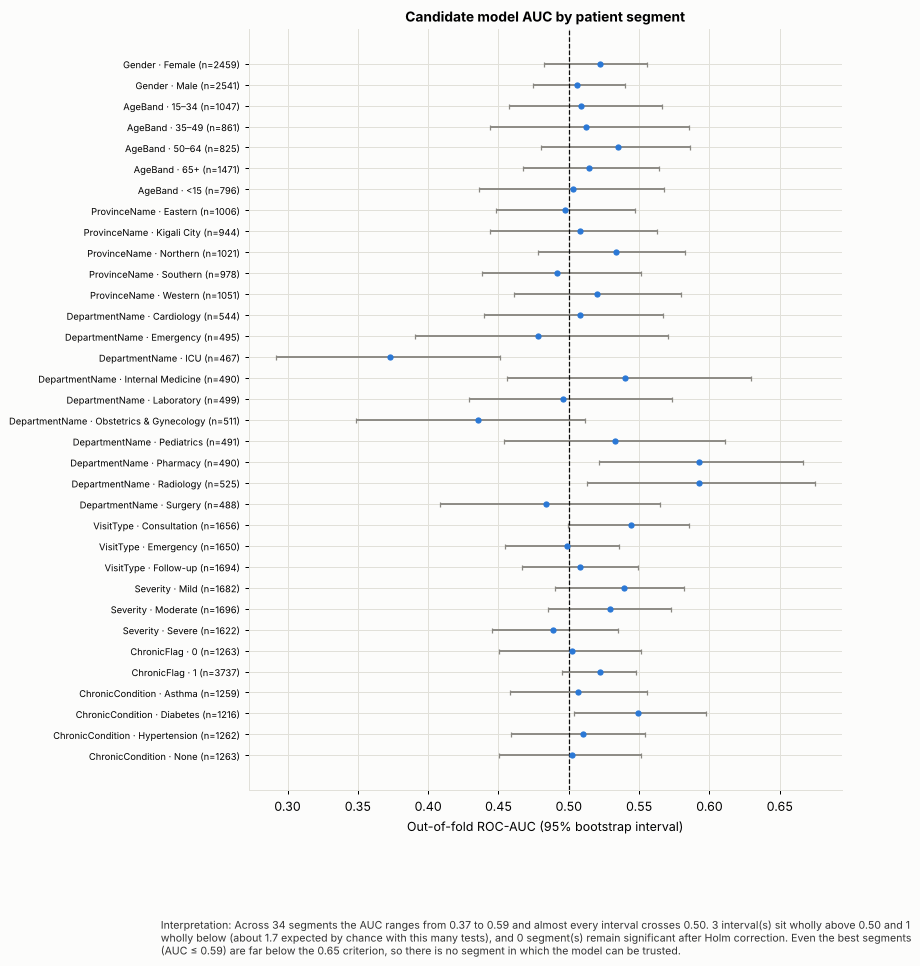

In [11]:
SEG = []
E2 = E.assign(oof=oof, AgeBand=pd.cut(E.Age, [0, 15, 35, 50, 65, 200], right=False, labels=["<15", "15–34", "35–49", "50–64", "65+"]).astype(str))
for col in ["Gender", "AgeBand", "ProvinceName", "DepartmentName", "VisitType", "Severity", "ChronicFlag", "ChronicCondition"]:
    for lev, g in E2.groupby(col):
        n_, pos_ = len(g), int(g.Admitted.sum())
        if pos_ < 30 or pos_ == n_: continue
        lo_, hi_ = boot_ci(g.Admitted.values, g.oof.values, n=400)
        SEG.append(dict(Segment=col, Level=str(lev), n=n_, Admissions=pos_, AUC=roc_auc_score(g.Admitted, g.oof), Lo=lo_, Hi=hi_,
                        p=stats.mannwhitneyu(g.oof[g.Admitted == 1], g.oof[g.Admitted == 0]).pvalue))
SEGD = pd.DataFrame(SEG); SEGD["p_holm"] = holm(SEGD.p.values); SEGD["CI_excludes_0.5"] = (SEGD.Lo > .5) | (SEGD.Hi < .5); SEGD.to_csv(TAB + "t_segment_auc.csv", index=False)
n_holm = int((SEGD.p_holm < .05).sum()); names_above = ", ".join(f"{a} {b} (AUC {c:.2f})" for a, b, c in SEGD[SEGD.Lo > .5][["Segment", "Level", "AUC"]].itertuples(index=False))
n_above = int((SEGD.Lo > .5).sum()); n_below = int((SEGD.Hi < .5).sum())
R["segments"] = dict(n=len(SEGD), holm_sig=n_holm, names_above=names_above, above=n_above, below=n_below, min_auc=float(SEGD.AUC.min()), max_auc=float(SEGD.AUC.max()), table=SEGD.round(3).to_dict("records"),
                     expected_chance=float(len(SEGD) * .05))
print(f"{len(SEGD)} segments assessed: AUC range {SEGD.AUC.min():.3f}–{SEGD.AUC.max():.3f}; CI entirely above 0.5 in {n_above}, entirely below in {n_below} (≈{len(SEGD) * .05:.1f} expected by chance); significant after Holm correction: {n_holm}. Intervals above 0.5: {names_above}")
record("T07", "Performance across segments (gender, age band, province, department, visit type, severity, chronic status)", "AUC consistently > 0.5 across segments; no segment where the model fails",
       f"{len(SEGD)} segments: AUC {SEGD.AUC.min():.2f}–{SEGD.AUC.max():.2f}; {n_above} intervals above and {n_below} below 0.5 (≈{len(SEGD) * .05:.1f} expected by chance); {n_holm} significant after Holm correction", n_holm >= max(3, .5 * len(SEGD)),
       "No segment where the model works reliably once multiple testing is accounted for; results scatter around 0.5", evidence="Fig. w04; table t_segment_auc.csv")
fig, ax = plt.subplots(figsize=(8.5, 0.27 * len(SEGD) + 1.8))
yy = np.arange(len(SEGD))[::-1]
ax.errorbar(SEGD.AUC, yy, xerr=[SEGD.AUC - SEGD.Lo, SEGD.Hi - SEGD.AUC], fmt="o", color=C[0], ecolor=MUTED, capsize=2, ms=4)
ax.axvline(.5, color=INK, ls="--", lw=1); ax.set_yticks(yy); ax.set_yticklabels([f"{a} · {b} (n={n})" for a, b, n in zip(SEGD.Segment, SEGD.Level, SEGD.n)], fontsize=7.5)
ax.set_xlabel("Out-of-fold ROC-AUC (95% bootstrap interval)"); ax.set_title("Candidate model AUC by patient segment")
save_fig(fig, "w04_segments", f"Across {len(SEGD)} segments the AUC ranges from {SEGD.AUC.min():.2f} to {SEGD.AUC.max():.2f} and almost every interval crosses 0.50. {n_above} interval(s) sit wholly above 0.50 and {n_below} wholly below (about {len(SEGD) * .05:.1f} expected by chance with this many tests), and {n_holm} segment(s) remain significant after Holm correction. Even the best segments (AUC ≤ {SEGD.AUC.max():.2f}) are far below the 0.65 criterion, so there is no segment in which the model can be trusted.", "Model performance by segment")
plt.show()

### D2. Overfitting check
Training-set AUC versus cross-validated AUC for the candidate and for more flexible models. A large gap means the model memorises noise; a small gap with AUC near 0.5 means there is nothing to learn.

                                              Model  Train_AUC  CV_AUC   Gap
                    Logistic regression (candidate)      0.601   0.520 0.081
                     Random forest (Week 6 setting)      0.943   0.502 0.441
                 Gradient boosting (Week 6 setting)      0.758   0.497 0.260
Random forest, unconstrained (deliberately overfit)      1.000   0.499 0.501
   n   rep  train  test
 500 1.000  0.781 0.466
1000 1.000  0.741 0.508
2000 1.000  0.669 0.496
3200 1.000  0.636 0.505
5000 1.000  0.613 0.509


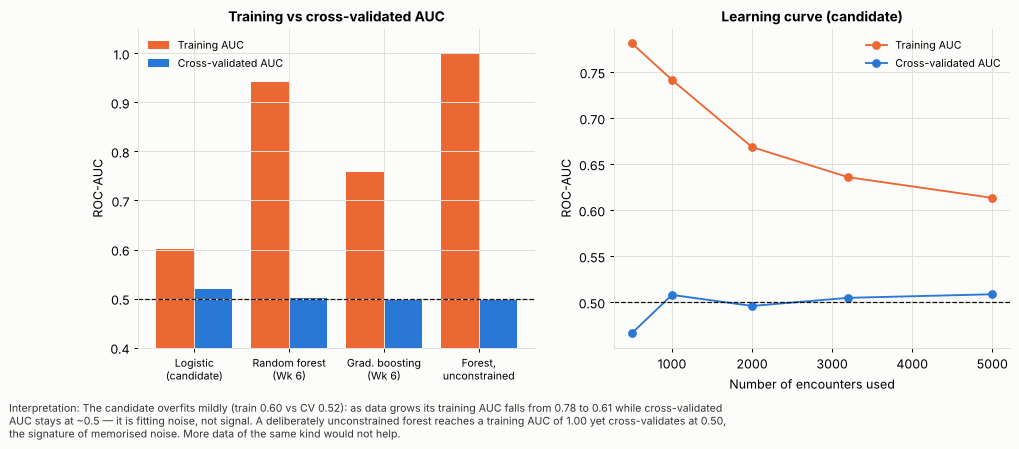

In [12]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
mods = {"Logistic regression (candidate)": cand,
        "Random forest (Week 6 setting)": lambda: make_pipe(RandomForestClassifier(300, min_samples_leaf=25, max_features="sqrt", n_jobs=2, random_state=SEED)),
        "Gradient boosting (Week 6 setting)": lambda: make_pipe(HistGradientBoostingClassifier(max_depth=3, learning_rate=.05, max_iter=120, l2_regularization=5, random_state=SEED)),
        "Random forest, unconstrained (deliberately overfit)": lambda: make_pipe(RandomForestClassifier(300, min_samples_leaf=1, max_features="sqrt", n_jobs=2, random_state=SEED))}
OV = []
for nm, mk in mods.items():
    tr = roc_auc_score(y, mk().fit(X, y).predict_proba(X)[:, 1])
    cvv = cross_validate(mk(), X, y, cv=cv5, scoring="roc_auc")["test_score"]
    OV.append(dict(Model=nm, Train_AUC=tr, CV_AUC=cvv.mean(), Gap=tr - cvv.mean()))
OV = pd.DataFrame(OV); OV.to_csv(TAB + "t_overfitting.csv", index=False); R["overfit"] = OV.round(4).to_dict("records")
sizes = [500, 1000, 2000, 3200, 5000]; LC = []
for n_ in sizes:
    for rep in range(3):
        ix = np.random.default_rng(rep).choice(len(y), n_, replace=False) if n_ < len(y) else np.arange(len(y))
        Xs, ys = X.iloc[ix], y[ix]
        if ys.sum() < 10: continue
        cvr_ = cross_validate(cand(), Xs, ys, cv=StratifiedKFold(5, shuffle=True, random_state=rep), scoring="roc_auc", return_train_score=True)
        LC.append(dict(n=n_, rep=rep, train=cvr_["train_score"].mean(), test=cvr_["test_score"].mean()))
LC = pd.DataFrame(LC).groupby("n").mean().reset_index(); R["learning_curve"] = LC.round(4).to_dict("records")
print(OV.round(3).to_string(index=False)); print(LC.round(3).to_string(index=False))
cand_gap = OV.iloc[0].Gap
record("T08", "Overfitting: train vs CV AUC; learning curve", "Small train–CV gap and CV AUC rising with more data", f"Candidate gap {cand_gap:.3f} (train {OV.iloc[0].Train_AUC:.3f}, CV {OV.iloc[0].CV_AUC:.3f}); learning-curve train AUC falls {LC.train.iloc[0]:.2f}→{LC.train.iloc[-1]:.2f} while CV stays ~0.5; unconstrained forest train {OV.iloc[3].Train_AUC:.3f} vs CV {OV.iloc[3].CV_AUC:.3f}",
       False, "Mild overfitting (train above CV) and no learning: CV AUC stays at ~0.5 as data grows while training AUC falls — the model fits noise. Flexible models only memorise it", evidence="Fig. w05; table t_overfitting.csv")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
xx = np.arange(len(OV)); ax[0].bar(xx - .2, OV.Train_AUC, .4, color=C[1], label="Training AUC"); ax[0].bar(xx + .2, OV.CV_AUC, .4, color=C[0], label="Cross-validated AUC"); ax[0].axhline(.5, color=INK, ls="--", lw=1)
ax[0].set_xticks(xx); ax[0].set_xticklabels(["Logistic\n(candidate)", "Random forest\n(Wk 6)", "Grad. boosting\n(Wk 6)", "Forest,\nunconstrained"], fontsize=8.5); ax[0].set_ylabel("ROC-AUC"); ax[0].set_ylim(.4, 1.05); ax[0].set_title("Training vs cross-validated AUC"); ax[0].legend(frameon=False, fontsize=8.5)
ax[1].plot(LC.n, LC.train, "o-", color=C[1], label="Training AUC"); ax[1].plot(LC.n, LC.test, "o-", color=C[0], label="Cross-validated AUC"); ax[1].axhline(.5, color=INK, ls="--", lw=1)
ax[1].set_xlabel("Number of encounters used"); ax[1].set_ylabel("ROC-AUC"); ax[1].set_title("Learning curve (candidate)"); ax[1].legend(frameon=False, fontsize=8.5)
save_fig(fig, "w05_overfitting", f"The candidate overfits mildly (train {OV.iloc[0].Train_AUC:.2f} vs CV {OV.iloc[0].CV_AUC:.2f}): as data grows its training AUC falls from {LC.train.iloc[0]:.2f} to {LC.train.iloc[-1]:.2f} while cross-validated AUC stays at ~0.5 — it is fitting noise, not signal. A deliberately unconstrained forest reaches a training AUC of {OV.iloc[3].Train_AUC:.2f} yet cross-validates at {OV.iloc[3].CV_AUC:.2f}, the signature of memorised noise. More data of the same kind would not help.", "Overfitting and learning-curve check")
plt.show()

### D3. Do the selected features support the prediction objective?
Permutation importance is computed on each of 5 held-out folds. With 18 features, the chance that a pure-noise feature shows positive importance in all 5 folds is 1/32 (3%), so about 0.6 features are expected to look "consistent" by luck.

In [13]:
IMP = []
for k_, (tr, te) in enumerate(cv5.split(X, y)):
    m_ = cand().fit(X.iloc[tr], y[tr]); r_ = permutation_importance(m_, X.iloc[te], y[te], scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
    IMP.append(pd.Series(r_.importances_mean, index=X.columns, name=k_))
IMP = pd.concat(IMP, axis=1); IMPS = pd.DataFrame({"Feature": IMP.index, "Mean": IMP.mean(1).values, "SD_between_folds": IMP.std(1).values, "Folds_positive": (IMP > 0).sum(1).values}).sort_values("Mean", ascending=False)
IMPS.to_csv(TAB + "t_feature_importance_folds.csv", index=False); n_cons = int((IMPS.Folds_positive == 5).sum())
R["importance"] = dict(n_features=len(IMPS), consistent=n_cons, expected_chance=float(len(IMPS) / 32), top=IMPS.head(5).round(4).to_dict("records"), max_mean=float(IMPS.Mean.max()))
w6 = json.load(open("../outputs/results.json"))["R"]
print(f"{n_cons} of {len(IMPS)} features positive in all 5 folds (≈{len(IMPS) / 32:.1f} expected by chance); largest mean importance {IMPS.Mean.max():.4f} AUC points")
print(f"Week 6 univariate screen (Data Analytics-style evidence): {w6['admission_factors_sig_raw']} of {w6['admission_factors_tested']} factors raw-significant, {w6['admission_factors_sig_holm']} after Holm correction")
LEAK = pd.DataFrame([["Age, BMI, RiskScore, ChronicFlag, ChronicCondition, demographics, geography, BloodGroup", "Yes", "Yes (feature set A)", "Known at registration"],
                     ["VisitType, DepartmentName, FacilityID, DayOfWeek, Month_, DoctorYearsExp", "Yes", "Yes (feature set A)", "Known when the appointment is booked"],
                     ["PatientVisits (appointments on record)", "Partly", "Yes (feature set A)", "Counted over the whole year, so it includes visits after the one being scored — mild look-ahead; recompute as 'visits before this date' in production"],
                     ["Diagnosis, Severity", "No — recorded at the visit", "No (feature set B only)", "Not available when predicting; excluded from deployment"],
                     ["LabDone, LabAbnormal, Prescription, Referred", "No — recorded during/after the visit", "No (feature set C only)", "Post-visit information (possible leakage); excluded from deployment"],
                     ["LengthOfStayDays, BillAmount, Rating", "No — outcome-linked", "Never used", "Would leak the outcome"]], columns=["Features", "Known at prediction time?", "In candidate?", "Note"])
LEAK.to_csv(TAB + "t_feature_timing_audit.csv", index=False); R["leak_audit"] = LEAK.to_dict("records")
record("T09", "Feature validity: per-fold permutation importance and prediction-time availability", "Some features contribute consistently; all features available at prediction time", f"{n_cons} of {len(IMPS)} features consistent across folds (≈{len(IMPS) / 32:.1f} by chance); max importance {IMPS.Mean.max():.4f}; one mild look-ahead feature found (PatientVisits)",
       False, "No feature contributes reliably; PatientVisits uses the full-year count (look-ahead) — must be 'visits before this appointment' in production", action="Documented in feature-timing audit and the input contract", evidence="Fig. w06; tables t_feature_importance_folds.csv, t_feature_timing_audit.csv")
IMPS.head(8)

1 of 18 features positive in all 5 folds (≈0.6 expected by chance); largest mean importance 0.0051 AUC points
Week 6 univariate screen (Data Analytics-style evidence): 2 of 26 factors raw-significant, 0 after Holm correction


,Feature,Mean,SD_between_folds,Folds_positive
15,DepartmentName,0.005,0.016,4
17,DayOfWeek,0.005,0.005,4
11,ProvinceName,0.004,0.009,4
2,RiskScore,0.003,0.001,5
3,DoctorYearsExp,0.003,0.002,4
8,MaritalStatus,0.003,0.002,4
12,BloodGroup,0.002,0.007,4
4,PatientVisits,0.002,0.002,3


### D4. Can this testing method detect a real signal? (negative control and planted-signal test)
A "no signal" verdict is only trustworthy if the same pipeline *would* have found a signal had one existed. Two checks: (1) a **negative control** — shuffled labels must give AUC ≈ 0.5; (2) a **planted-signal test** — we simulate outcomes that genuinely depend on Age with known strength and confirm the pipeline recovers them.

Negative control: shuffled-label AUC mean 0.501, sd 0.018 (should be ~0.5); observed 0.520 -> permutation p = 0.188
 Planted_effect  True_AUC_of_signal  Pipeline_CV_AUC  Perm_p  Detected
          0.000               0.516            0.512   0.194     False
          0.200               0.567            0.542   0.032      True
          0.400               0.617            0.590   0.032      True
          0.600               0.676            0.658   0.032      True
          0.900               0.746            0.731   0.032      True
Smallest planted signal detected: true AUC ≈ 0.57


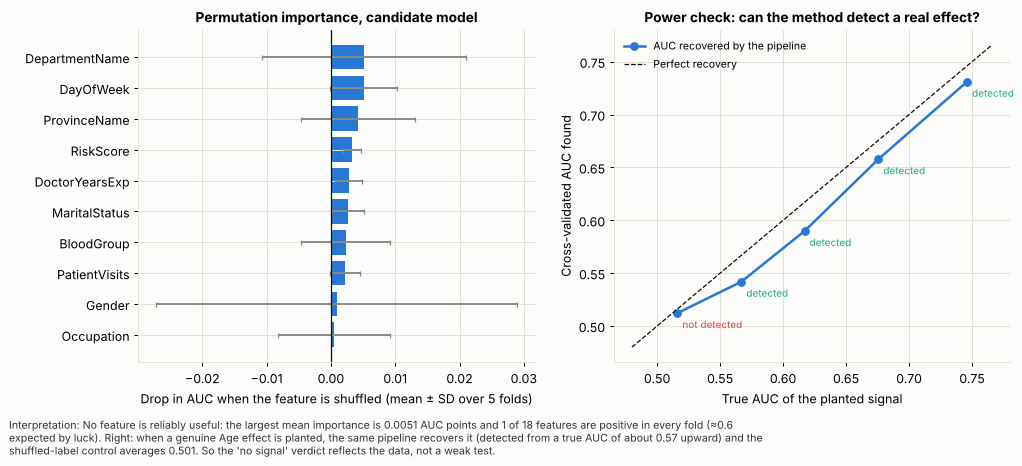

In [14]:
obs5 = cross_validate(cand(), X, y, cv=cv5, scoring="roc_auc")["test_score"].mean()
null = np.array([cross_validate(cand(), X, rng.permutation(y), cv=cv5, scoring="roc_auc")["test_score"].mean() for _ in range(100)])
p_perm = (1 + (null >= obs5).sum()) / (1 + len(null))
print(f"Negative control: shuffled-label AUC mean {null.mean():.3f}, sd {null.std():.3f} (should be ~0.5); observed {obs5:.3f} -> permutation p = {p_perm:.3f}")
from scipy.optimize import brentq
zA = ((E.Age - E.Age.mean()) / E.Age.std()).values; PL = []
for b in [0.0, 0.2, 0.4, 0.6, 0.9]:
    a_ = brentq(lambda a: (1 / (1 + np.exp(-(a + b * zA)))).mean() - prev, -10, 5)
    ysim = (np.random.default_rng(7).random(len(zA)) < 1 / (1 + np.exp(-(a_ + b * zA)))).astype(int)
    true_auc = roc_auc_score(ysim, zA); cvs = cross_validate(cand(), X, ysim, cv=cv5, scoring="roc_auc")["test_score"].mean()
    nl = np.array([cross_validate(cand(), X, np.random.default_rng(100 + i).permutation(ysim), cv=cv5, scoring="roc_auc")["test_score"].mean() for i in range(30)])
    PL.append(dict(Planted_effect=b, True_AUC_of_signal=true_auc, Pipeline_CV_AUC=cvs, Perm_p=(1 + (nl >= cvs).sum()) / 31, Detected=(1 + (nl >= cvs).sum()) / 31 < .05))
PL = pd.DataFrame(PL); PL.to_csv(TAB + "t_planted_signal_power.csv", index=False)
R["negative_control"] = dict(null_mean=float(null.mean()), null_sd=float(null.std()), obs=float(obs5), p=float(p_perm)); R["planted"] = PL.round(4).to_dict("records")
mind = PL[PL.Detected].True_AUC_of_signal.min() if PL.Detected.any() else np.nan
R["min_detectable_auc"] = float(mind) if mind == mind else None
print(PL.round(3).to_string(index=False)); print(f"Smallest planted signal detected: true AUC ≈ {mind:.2f}")
record("T10", "Negative control (shuffled labels)", "Mean AUC ≈ 0.50 (pipeline free of leakage/bias)", f"Shuffled mean {null.mean():.3f} (sd {null.std():.3f}); observed {obs5:.3f}, permutation p = {p_perm:.2f}", abs(null.mean() - .5) < .01, evidence="notebook D4")
record("T11", "Planted-signal detection (can the method find a real effect?)", "Pipeline recovers a planted Age effect and flags it significant", f"Detected from true AUC ≈ {mind:.2f} upward; with no planted effect, no detection", bool(PL.Detected.any()) and not bool(PL.iloc[0].Detected),
       evidence="Fig. w06; table t_planted_signal_power.csv")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8))
top = IMPS.head(10).iloc[::-1]; ax[0].barh(top.Feature, top.Mean, xerr=top.SD_between_folds, color=C[0], ecolor=MUTED, capsize=2); ax[0].axvline(0, color=INK, lw=1)
ax[0].set_xlabel("Drop in AUC when the feature is shuffled (mean ± SD over 5 folds)"); ax[0].set_title("Permutation importance, candidate model")
ax[1].plot(PL.True_AUC_of_signal, PL.Pipeline_CV_AUC, "o-", color=C[0], lw=2, label="AUC recovered by the pipeline"); ax[1].plot([.48, PL.True_AUC_of_signal.max() + .02], [.48, PL.True_AUC_of_signal.max() + .02], color=INK, ls="--", lw=1, label="Perfect recovery")
for _, r_ in PL.iterrows(): ax[1].annotate("detected" if r_.Detected else "not detected", (r_.True_AUC_of_signal, r_.Pipeline_CV_AUC), textcoords="offset points", xytext=(4, -12), fontsize=8, color=C[2] if r_.Detected else C[7])
ax[1].set_xlabel("True AUC of the planted signal"); ax[1].set_ylabel("Cross-validated AUC found"); ax[1].set_title("Power check: can the method detect a real effect?"); ax[1].legend(frameon=False, fontsize=8.5)
save_fig(fig, "w06_importance_power", f"No feature is reliably useful: the largest mean importance is {IMPS.Mean.max():.4f} AUC points and {n_cons} of {len(IMPS)} features are positive in every fold (≈{len(IMPS) / 32:.1f} expected by luck). Right: when a genuine Age effect is planted, the same pipeline recovers it (detected from a true AUC of about {mind:.2f} upward) and the shuffled-label control averages {null.mean():.3f}. So the 'no signal' verdict reflects the data, not a weak test.", "Feature importance and planted-signal power check")
plt.show()

## E. Evidence-based refinement and re-test
Testing showed (i) no discrimination, (ii) noisy one-hot categories (department, weekday, province) driving the flags, (iii) mild overfitting, (iv) uninformative probabilities.
Each refinement below addresses one of those findings. **Selection uses the development set only** (4,000 encounters, repeated 5×3-fold CV, identical folds for every model); the hold-out is opened once, at the end.
Refinements are accepted only if they beat the candidate by ≥ 0.02 AUC with a significant *corrected resampled t-test* (Nadeau–Bengio; it allows for overlapping training sets).

In [15]:
CLIN_NUM, CLIN_CAT = ["Age", "BMI", "RiskScore", "ChronicFlag"], ["VisitType", "Gender", "DepartmentName"]
def lr_l1():
    try: return LogisticRegression(l1_ratio=1, solver="saga", C=.05, max_iter=5000)
    except Exception: return LogisticRegression(penalty="l1", solver="liblinear", C=.05, max_iter=5000)
VARIANTS = {
    "Baseline (prior probability)": baseline,
    "Rule only (RiskScore)": lambda: make_pipe(LogisticRegression(C=1, max_iter=2000), ["RiskScore"], []),
    "Candidate (Week 6)": cand,
    "R1 Clinical-core features": lambda: make_pipe(LogisticRegression(C=.1, max_iter=2000), CLIN_NUM, CLIN_CAT),
    "R2a Stronger L2 (C=0.01)": lambda: make_pipe(LogisticRegression(C=.01, max_iter=2000)),
    "R2b L1 feature selection": lambda: make_pipe(lr_l1()),
    "R3 Balanced class weights": lambda: make_pipe(LogisticRegression(C=.1, max_iter=2000, class_weight="balanced")),
    "R4 Shallow gradient boosting": lambda: make_pipe(HistGradientBoostingClassifier(max_depth=2, learning_rate=.03, max_iter=80, min_samples_leaf=60, l2_regularization=10, random_state=SEED)),
    "R5 Candidate + isotonic calibration": lambda: CalibratedClassifierCV(cand(), method="isotonic", cv=5),
}
FOLD = {}; rows = []
for nm, mk in VARIANTS.items():
    cr_ = cv_scores(mk, Xdev, ydev); FOLD[nm] = cr_["test_auc"]
    rows.append(dict(Model=nm, AUC=cr_["test_auc"].mean(), AUC_sd=cr_["test_auc"].std(), PR_AUC=cr_["test_ap"].mean(), Brier=-cr_["test_brier"].mean()))
VT = pd.DataFrame(rows); base_f = FOLD["Candidate (Week 6)"]; n_f = len(base_f); corr = 1 / n_f + 1 / 4
def corrected_t(d):
    d = np.asarray(d); m_ = d.mean(); v = d.var(ddof=1) * corr
    if v <= 0: return m_, np.nan, np.nan, (np.nan, np.nan)
    t = m_ / np.sqrt(v); p = 2 * stats.t.sf(abs(t), n_f - 1); h = stats.t.ppf(.975, n_f - 1) * np.sqrt(v); return m_, t, p, (m_ - h, m_ + h)
dl = [corrected_t(FOLD[n] - base_f) for n in VT.Model]
VT["dAUC_vs_candidate"] = [d[0] for d in dl]; VT["dAUC_lo"] = [d[3][0] for d in dl]; VT["dAUC_hi"] = [d[3][1] for d in dl]; VT["p_corrected_t"] = [d[2] for d in dl]
VT.to_csv(TAB + "t_refinement_dev_cv.csv", index=False); R["refine_dev"] = VT.round(4).to_dict("records")
R["dev_prev"] = float(ydev.mean())
print(VT.round(4).to_string(index=False))
cands_ref = VT[VT.Model.str.match(r"R[1-4]")]; best_ref = cands_ref.sort_values("AUC", ascending=False).iloc[0]
accepted = (best_ref.dAUC_vs_candidate >= .02) and (best_ref.p_corrected_t < .05)
print(f"\nBest refinement on dev CV: {best_ref.Model} (ΔAUC {best_ref.dAUC_vs_candidate:+.4f}, corrected-t p = {best_ref.p_corrected_t:.3f}) -> meaningful improvement: {accepted}")
R["best_refinement"] = dict(name=best_ref.Model, d=float(best_ref.dAUC_vs_candidate), p=float(best_ref.p_corrected_t), accepted=bool(accepted))
record("T12", "Refinement comparison on development CV (7 variants vs candidate)", "At least one refinement beats the candidate by ≥ 0.02 AUC (corrected-t p < 0.05)", f"Best: {best_ref.Model}, ΔAUC {best_ref.dAUC_vs_candidate:+.3f} (p = {best_ref.p_corrected_t:.2f}); R5 calibration changes Brier {VT.iloc[-1].Brier - VT.iloc[2].Brier:+.4f}",
       bool(accepted), "No refinement produced a meaningful improvement" if not accepted else "", "Refinements tried: clinical-core features, L2/L1 regularisation, class weights, shallow boosting, isotonic calibration", evidence="Fig. w07; table t_refinement_dev_cv.csv")

                              Model   AUC  AUC_sd  PR_AUC  Brier  dAUC_vs_candidate  dAUC_lo  dAUC_hi  p_corrected_t
       Baseline (prior probability) 0.500   0.000   0.117  0.103              0.018   -0.007    0.044          0.149
              Rule only (RiskScore) 0.517   0.025   0.123  0.103              0.035   -0.008    0.079          0.101
                 Candidate (Week 6) 0.481   0.021   0.118  0.105              0.000      NaN      NaN            NaN
          R1 Clinical-core features 0.501   0.018   0.126  0.104              0.019   -0.006    0.045          0.128
           R2a Stronger L2 (C=0.01) 0.485   0.021   0.117  0.104              0.003   -0.010    0.017          0.628
           R2b L1 feature selection 0.491   0.024   0.119  0.104              0.010   -0.023    0.043          0.530
          R3 Balanced class weights 0.479   0.021   0.117  0.249             -0.002   -0.010    0.005          0.557
       R4 Shallow gradient boosting 0.475   0.027   0.112  0.104

HOLD-OUT (opened once): baseline AUC 0.500 | candidate 0.529 (95% CI 0.47–0.59) | refined [R1 Clinical-core features] 0.537 (95% CI 0.48–0.59); paired ΔAUC +0.008 (95% CI -0.040 to +0.060)
Refined: 30-split mean AUC 0.514, 63% above 0.5 | time-split AUC 0.488 (CI 0.44–0.53) | calibration slope 0.24, Brier 0.1037 | top-20% precision 0.130 recall 0.222
Isotonic calibration of the candidate: Brier 0.1043 -> 0.1037 (baseline 0.1035)


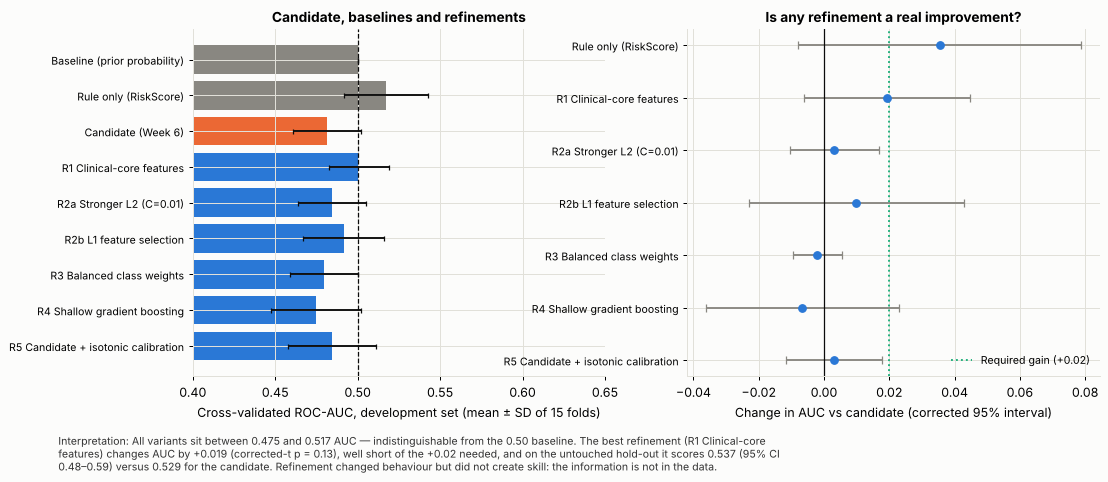

In [16]:
# ---- open the hold-out once: baseline, candidate, selected refinement ----
REF_NAME = best_ref.Model; REF_MK = VARIANTS[REF_NAME]
mr = REF_MK().fit(Xdev, ydev); p_ho_r = mr.predict_proba(Xho)[:, 1]; auc_ho_r = roc_auc_score(yho, p_ho_r); ci_r = boot_ci(yho, p_ho_r); ci_c = boot_ci(yho, p_ho0)
ap_c, ap_r = average_precision_score(yho, p_ho0), average_precision_score(yho, p_ho_r)
rb = np.random.default_rng(SEED); dd = []
for _ in range(1000):
    ix = rb.integers(0, len(yho), len(yho))
    if len(np.unique(yho[ix])) == 2: dd.append(roc_auc_score(yho[ix], p_ho_r[ix]) - roc_auc_score(yho[ix], p_ho0[ix]))
d_ci = (float(np.percentile(dd, 2.5)), float(np.percentile(dd, 97.5)))
# refined: 30-split stability, time split, calibration (out-of-fold on all encounters)
a30r = []
for s_ in range(30):
    a, b, ya, yb = train_test_split(X, y, test_size=.2, stratify=y, random_state=1000 + s_); a30r.append(roc_auc_score(yb, REF_MK().fit(a, ya).predict_proba(b)[:, 1]))
a30r = np.array(a30r); mtr = REF_MK().fit(X[tr_m], y[tr_m]); ptr = mtr.predict_proba(X[~tr_m])[:, 1]; auc_time_r = roc_auc_score(y[~tr_m], ptr); ci_time_r = boot_ci(y[~tr_m], ptr)
oof_r = cross_val_predict(REF_MK(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
lgr = np.log(np.clip(oof_r, 1e-6, 1 - 1e-6) / (1 - np.clip(oof_r, 1e-6, 1 - 1e-6))); slope_r = float(LogisticRegression(C=1e6, max_iter=1000).fit(lgr.reshape(-1, 1), y).coef_[0][0]); brier_r = brier_score_loss(y, oof_r)
cap_r = (p_ho_r >= np.quantile(p_ho_r, .8)); prec_r = precision_score(yho, cap_r, zero_division=0); rec_r = recall_score(yho, cap_r)
cal_oof = cross_val_predict(VARIANTS["R5 Candidate + isotonic calibration"](), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
brier_cal = brier_score_loss(y, cal_oof)
R["holdout_final"] = dict(cand=dict(auc=float(auc_ho0), lo=ci_c[0], hi=ci_c[1], ap=float(ap_c)), ref=dict(name=REF_NAME, auc=float(auc_ho_r), lo=ci_r[0], hi=ci_r[1], ap=float(ap_r), precision20=float(prec_r), recall20=float(rec_r)),
                         delta=float(auc_ho_r - auc_ho0), delta_ci=d_ci, prevalence=float(yho.mean()),
                         stability_ref=dict(mean=float(a30r.mean()), share=float((a30r > .5).mean()), lo=float(a30r.min()), hi=float(a30r.max())), time_ref=dict(auc=float(auc_time_r), ci=ci_time_r),
                         calib_ref=dict(slope=slope_r, brier=float(brier_r)), brier_calibrated=float(brier_cal), brier_candidate=float(brier), brier_base=float(brier_base))
print(f"HOLD-OUT (opened once): baseline AUC 0.500 | candidate {auc_ho0:.3f} (95% CI {ci_c[0]:.2f}–{ci_c[1]:.2f}) | refined [{REF_NAME}] {auc_ho_r:.3f} (95% CI {ci_r[0]:.2f}–{ci_r[1]:.2f}); paired ΔAUC {auc_ho_r - auc_ho0:+.3f} (95% CI {d_ci[0]:+.3f} to {d_ci[1]:+.3f})")
print(f"Refined: 30-split mean AUC {a30r.mean():.3f}, {(a30r > .5).mean():.0%} above 0.5 | time-split AUC {auc_time_r:.3f} (CI {ci_time_r[0]:.2f}–{ci_time_r[1]:.2f}) | calibration slope {slope_r:.2f}, Brier {brier_r:.4f} | top-20% precision {prec_r:.3f} recall {rec_r:.3f}")
print(f"Isotonic calibration of the candidate: Brier {brier:.4f} -> {brier_cal:.4f} (baseline {brier_base:.4f})")
record("T13", "Re-test of refined model on untouched hold-out", "Refined AUC ≥ 0.65 with lower CI bound > 0.5 (C1, C2)", f"{REF_NAME}: AUC {auc_ho_r:.3f} (95% CI {ci_r[0]:.2f}–{ci_r[1]:.2f}); candidate {auc_ho0:.3f}; paired Δ {auc_ho_r - auc_ho0:+.3f} (95% CI {d_ci[0]:+.3f} to {d_ci[1]:+.3f})", ci_r[0] > .5 and auc_ho_r >= .65,
       "Refinement does not create skill", evidence="Fig. w07")
record("T14", "Re-test: stability and time-based split of refined model", "AUC > 0.5 in ≥ 90% of splits and in the time split (C4)", f"{(a30r > .5).mean():.0%} of splits above 0.5 (mean {a30r.mean():.3f}); time split {auc_time_r:.3f} (CI {ci_time_r[0]:.2f}–{ci_time_r[1]:.2f})", (a30r > .5).mean() >= .9 and ci_time_r[0] > .5, evidence="notebook E")
record("T15", "Re-test: calibration after refinement (slope; isotonic recalibration)", "Slope within 0.8–1.2 and Brier below baseline (C5)", f"Refined slope {slope_r:.2f}, Brier {brier_r:.4f}; isotonic-calibrated candidate Brier {brier_cal:.4f} vs baseline {brier_base:.4f}", 0.8 <= slope_r <= 1.2 and brier_r < brier_base,
       "Recalibration can only push predictions toward the average rate (Brier ≈ baseline); it cannot add information", evidence="notebook E")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
vt = VT.copy(); yy = np.arange(len(vt))[::-1]
ax[0].barh(yy, vt.AUC, xerr=vt.AUC_sd, color=[C[1] if "Candidate (Week 6)" == m else (MUTED if m.startswith(("Baseline", "Rule")) else C[0]) for m in vt.Model], ecolor=INK, capsize=2); ax[0].axvline(.5, color=INK, ls="--", lw=1)
ax[0].set_yticks(yy); ax[0].set_yticklabels(vt.Model, fontsize=8.5); ax[0].set_xlim(.4, .65); ax[0].set_xlabel("Cross-validated ROC-AUC, development set (mean ± SD of 15 folds)"); ax[0].set_title("Candidate, baselines and refinements")
rf = VT[VT.Model.str.startswith("R")]; yy2 = np.arange(len(rf))[::-1]
ax[1].errorbar(rf.dAUC_vs_candidate, yy2, xerr=[rf.dAUC_vs_candidate - rf.dAUC_lo, rf.dAUC_hi - rf.dAUC_vs_candidate], fmt="o", color=C[0], ecolor=MUTED, capsize=3); ax[1].axvline(0, color=INK, lw=1); ax[1].axvline(.02, color=C[2], ls=":", lw=1.5, label="Required gain (+0.02)")
ax[1].set_yticks(yy2); ax[1].set_yticklabels(rf.Model, fontsize=8.5); ax[1].set_xlabel("Change in AUC vs candidate (corrected 95% interval)"); ax[1].set_title("Is any refinement a real improvement?"); ax[1].legend(frameon=False, fontsize=8.5)
save_fig(fig, "w07_refinement", f"All variants sit between {VT.AUC.min():.3f} and {VT.AUC.max():.3f} AUC — indistinguishable from the 0.50 baseline. The best refinement ({REF_NAME}) changes AUC by {best_ref.dAUC_vs_candidate:+.3f} (corrected-t p = {best_ref.p_corrected_t:.2f}), well short of the +0.02 needed, and on the untouched hold-out it scores {auc_ho_r:.3f} (95% CI {ci_r[0]:.2f}–{ci_r[1]:.2f}) versus {auc_ho0:.3f} for the candidate. Refinement changed behaviour but did not create skill: the information is not in the data.", "Before/after: candidate vs refinements")
plt.show()

### E1. Acceptance criteria — final verdict
The pre-registered criteria from section A, evaluated for the Week 6 candidate and for the best refinement.

In [17]:
def crit_row(name, auc_, lo_, ap_, share_, time_lo_, slope_, fold_auc):
    m_, t_, p_, ci_ = corrected_t(np.asarray(fold_auc) - .5)
    return {"Model": name, "C1 AUC ≥ 0.65": (f"{auc_:.3f}", auc_ >= .65), "C2 CI lower > 0.5": (f"{lo_:.3f}", lo_ > .5), "C3 PR-AUC ≥ 1.5×prevalence": (f"{ap_:.3f} vs {1.5 * yho.mean():.3f}", ap_ >= 1.5 * yho.mean()),
            "C4 stable (≥90% splits >0.5 and time-split CI lower >0.5)": (f"{share_:.0%} / {time_lo_:.2f}", share_ >= .9 and time_lo_ > .5), "C5 slope 0.8–1.2": (f"{slope_:.2f}", .8 <= slope_ <= 1.2),
            "C6 beats baseline (corrected CI of AUC−0.5 excludes 0)": (f"{ci_[0]:+.3f} to {ci_[1]:+.3f}", ci_[0] > 0)}
CR = [crit_row("Candidate (Week 6)", auc_ho0, ci_c[0], ap_c, (aucs30 > .5).mean(), ci_time[0], slope, FOLD["Candidate (Week 6)"]),
      crit_row(f"Refined ({REF_NAME})", auc_ho_r, ci_r[0], ap_r, (a30r > .5).mean(), ci_time_r[0], slope_r, FOLD[REF_NAME])]
CRT = pd.DataFrame([{k: (v if k == "Model" else f"{v[0]}  [{'PASS' if v[1] else 'FAIL'}]") for k, v in r_.items()} for r_ in CR]).set_index("Model").T
n_pass = [sum(v[1] for k, v in r_.items() if k != "Model") for r_ in CR]; R["criteria"] = dict(table=CRT.reset_index().to_dict("records"), passed=n_pass, total=6)
CRT.to_csv(TAB + "t_acceptance_criteria.csv"); print(CRT.to_string()); print(f"\nCriteria passed — candidate: {n_pass[0]}/6, refined: {n_pass[1]}/6")
SUITABLE = n_pass[1] == 6 or n_pass[0] == 6; R["suitable_patient_level"] = bool(SUITABLE)
CRT

Model                                                            Candidate (Week 6) Refined (R1 Clinical-core features)
C1 AUC ≥ 0.65                                                         0.529  [FAIL]                       0.537  [FAIL]
C2 CI lower > 0.5                                                     0.470  [FAIL]                       0.485  [FAIL]
C3 PR-AUC ≥ 1.5×prevalence                                   0.145 vs 0.176  [FAIL]              0.145 vs 0.176  [FAIL]
C4 stable (≥90% splits >0.5 and time-split CI lower >0.5)        40% / 0.43  [FAIL]                  63% / 0.44  [FAIL]
C5 slope 0.8–1.2                                                       0.18  [FAIL]                        0.24  [FAIL]
C6 beats baseline (corrected CI of AUC−0.5 excludes 0)     -0.044 to +0.007  [FAIL]            -0.022 to +0.024  [FAIL]

Criteria passed — candidate: 0/6, refined: 0/6


Model,Candidate (Week 6),Refined (R1 Clinical-core features)
C1 AUC ≥ 0.65,0.529 [FAIL],0.537 [FAIL]
C2 CI lower > 0.5,0.470 [FAIL],0.485 [FAIL]
C3 PR-AUC ≥ 1.5×prevalence,0.145 vs 0.176 [FAIL],0.145 vs 0.176 [FAIL]
C4 stable (≥90% splits >0.5 and time-split CI lower >0.5),40% / 0.43 [FAIL],63% / 0.44 [FAIL]
C5 slope 0.8–1.2,0.18 [FAIL],0.24 [FAIL]
C6 beats baseline (corrected CI of AUC−0.5 excludes 0),-0.044 to +0.007 [FAIL],-0.022 to +0.024 [FAIL]


## F. Cross-track test: Data Science → ML Engineering (model hand-off and scoring interface)
ML Engineering will wrap the model in a pipeline. The Week 7 matrix asks Data Science to *test whether the integrated pipeline correctly handles model requirements and expected inputs/outputs*.
We test the Week 6 scoring behaviour (**V1** = bare model call) against an explicit **input/output contract**, fix what fails (**V2**) and re-test.
Test cases cover valid, malformed, out-of-range, missing, unseen and empty inputs, ordering, persistence, determinism, output schema and speed.
**Scope note:** these tests were designed and run on the Data Science side; the ML Engineering teammate's own run and sign-off must be recorded separately (placeholders in the cross-track record).

In [18]:
import time, tempfile
FINAL_MK = REF_MK if accepted else cand; FINAL_NAME = REF_NAME if accepted else "Candidate (Week 6), unchanged"
pipe_final = FINAL_MK().fit(X, y); oof_f = cross_val_predict(FINAL_MK(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
cuts = dict(high=float(np.quantile(oof_f, .8)), low=float(np.quantile(oof_f, .2))); train_cats = {c: sorted(X[c].astype(str).unique()) for c in ars.CONTRACT["categorical"]}
V1 = ars.AdmissionScorerV1(pipe_final); V2 = ars.AdmissionScorerV2(pipe_final, train_cats, cuts)
print("Final model wrapped by the scorer:", FINAL_NAME)
# does the contract accept every real record?
rng_viol = {}
for c, (lo, hi, _) in ars.CONTRACT["numeric"].items():
    v = int(((X[c] < lo) | (X[c] > hi)).sum()); rng_viol[c] = v
print("Real records outside the contract ranges:", {k: v for k, v in rng_viol.items() if v} or "none")
for c, allowed in ars.CONTRACT["categorical"].items():
    if allowed is not None: assert X[c].isin(allowed).all(), f"contract list for {c} does not cover the data: {sorted(set(X[c]) - set(allowed))}"
w_all, _ = V2.validate(X); print("Contract accepts all 5,000 real records; warnings on real data:", sum(len(w) > 0 for w in w_all))

Final model wrapped by the scorer: Candidate (Week 6), unchanged
Real records outside the contract ranges: none
Contract accepts all 5,000 real records; warnings on real data: 0


 ID                                                  Scenario   V1   V2
X01                                       Valid single record PASS PASS
X02                                        Valid batch of 200 PASS PASS
X03                              Columns in a different order PASS PASS
X04                Unexpected extra column (e.g. PatientName) FAIL PASS
X05                             Required column missing (Age) PASS PASS
X06 Unseen category in an open field (Occupation = Astronaut) FAIL PASS
X07   Impossible value in a closed list (ProvinceName = Mars) FAIL PASS
X08                Out-of-range numbers (Age = -5, BMI = 500) FAIL PASS
X09                         Missing numeric value (Age = NaN) FAIL PASS
X10                           Wrong data type (Age = 'forty') FAIL PASS
X11                                      Empty input (0 rows) FAIL PASS
X12                            Determinism (same input twice) PASS PASS
X13                  Persistence (save and reload the scorer) PA

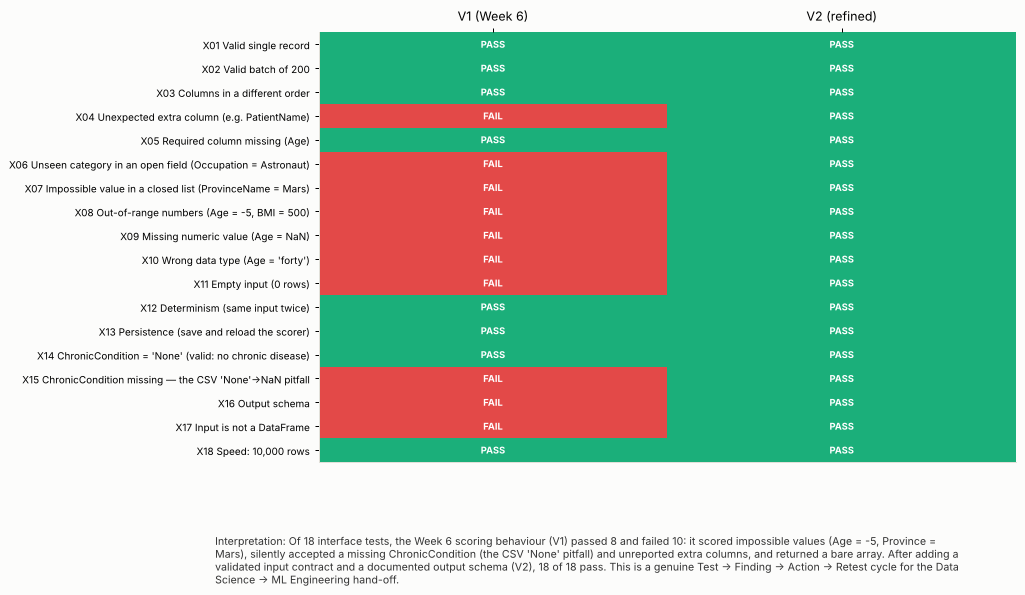

In [19]:
def scores(o): return o["risk_score"].values if isinstance(o, pd.DataFrame) else np.asarray(o)
def attempt(sc, df):
    try: return "ok", sc.predict(df)
    except Exception as e: return "error", f"{type(e).__name__}: {e}"
base = X.iloc[:200].copy().reset_index(drop=True); row = base.iloc[[0]].copy(); ref_scores = pipe_final.predict_proba(base)[:, 1]
def warn_text(o): return " ".join(o["warnings"].astype(str)) if isinstance(o, pd.DataFrame) else ""
def t_valid_single(sc):
    k, o = attempt(sc, row); ok = k == "ok" and len(scores(o)) == 1 and 0 <= scores(o)[0] <= 1; return ok, "scored, p=%.3f" % scores(o)[0] if k == "ok" else o
def t_valid_batch(sc):
    k, o = attempt(sc, base); ok = k == "ok" and len(scores(o)) == 200 and np.isfinite(scores(o)).all(); return ok, "200 finite scores" if ok else str(o)[:100]
def t_order(sc):
    k, o = attempt(sc, base[base.columns[::-1]]); ok = k == "ok" and np.allclose(scores(o), ref_scores); return ok, "identical scores" if ok else str(o)[:100]
def t_extra(sc):
    d = base.copy(); d["PatientName"] = "X"; k, o = attempt(sc, d); ok = k == "ok" and "PatientName" in warn_text(o); return ok, ("scored and extra column reported" if ok else ("scored silently; extra column (possible identifier) not reported" if k == "ok" else str(o)[:100]))
def t_missing_col(sc):
    k, o = attempt(sc, base.drop(columns=["Age"])); ok = k == "error" and "Age" in o; return ok, o[:110] if k == "error" else "scored without Age"
def t_unseen_free(sc):
    d = row.copy(); d["Occupation"] = "Astronaut"; k, o = attempt(sc, d); ok = k == "ok" and "Astronaut" in warn_text(o); return ok, ("scored with warning" if ok else ("scored silently; unseen category not reported" if k == "ok" else o[:110]))
def t_closed_list(sc):
    d = row.copy(); d["ProvinceName"] = "Mars"; k, o = attempt(sc, d); ok = k == "error" and "ProvinceName" in o; return ok, o[:110] if k == "error" else "scored an impossible province without complaint"
def t_range(sc):
    d = row.copy(); d["Age"] = -5; d["BMI"] = 500; k, o = attempt(sc, d); ok = k == "error" and "Age" in o; return ok, o[:110] if k == "error" else "scored Age=-5, BMI=500 without complaint"
def t_nan(sc):
    d = row.copy(); d["Age"] = np.nan; k, o = attempt(sc, d); ok = k == "error" and "Age" in o; return ok, o[:110]
def t_type(sc):
    d = row.copy().astype({"Age": object}); d["Age"] = "forty"; k, o = attempt(sc, d); ok = k == "error" and "Age" in o; return ok, o[:110] if k == "error" else "scored text age"
def t_empty(sc):
    k, o = attempt(sc, base.iloc[0:0]); ok = k == "ok" and len(o) == 0; return ok, "empty result" if ok else str(o)[:110]
def t_determinism(sc):
    k1, o1 = attempt(sc, base); k2, o2 = attempt(sc, base); ok = k1 == k2 == "ok" and np.array_equal(scores(o1), scores(o2)); return ok, "identical on repeat" if ok else "differs"
def t_persist(sc):
    f = tempfile.mktemp(suffix=".joblib"); joblib.dump(sc, f); sc2 = joblib.load(f); k, o1 = attempt(sc, base); k2, o2 = attempt(sc2, base); ok = k == k2 == "ok" and np.allclose(scores(o1), scores(o2)); os.remove(f); return ok, "identical after save/load" if ok else "differs"
def t_none_literal(sc):
    d = row.copy(); d["ChronicCondition"] = "None"; k, o = attempt(sc, d); ok = k == "ok"; return ok, "'None' accepted as a value" if ok else str(o)[:110]
def t_csv_none(sc):  # naive pandas read turns 'None' into NaN
    d = row.copy(); d["ChronicCondition"] = np.nan; k, o = attempt(sc, d); ok = k == "error" and "ChronicCondition" in o; return ok, o[:120] if k == "error" else "scored a missing ChronicCondition silently (NaN treated as a category)"
def t_schema(sc):
    k, o = attempt(sc, row); want = ["risk_score", "risk_band", "warnings", "model_version", "use_caution"]; ok = k == "ok" and isinstance(o, pd.DataFrame) and all(c in o.columns for c in want); return ok, "output schema as documented" if ok else "bare array: no band, warnings, version or caution flag"
def t_nondf(sc):
    k, o = attempt(sc, row.iloc[0].to_dict()); ok = k == "error" and "DataFrame" in o; return ok, o[:110] if k == "error" else "scored a dict"
def t_speed(sc):
    big = pd.concat([X] * 2, ignore_index=True); t0 = time.time(); k, o = attempt(sc, big); dt = time.time() - t0; ok = k == "ok" and dt < 5; return ok, f"10,000 rows in {dt:.2f}s"
TC = [("X01", "Valid single record", "Returns one probability in [0, 1]", t_valid_single), ("X02", "Valid batch of 200", "200 finite probabilities", t_valid_batch),
      ("X03", "Columns in a different order", "Identical scores (columns matched by name)", t_order), ("X04", "Unexpected extra column (e.g. PatientName)", "Scored; ignored column reported (identifier safety)", t_extra),
      ("X05", "Required column missing (Age)", "Clear error naming 'Age'", t_missing_col), ("X06", "Unseen category in an open field (Occupation = Astronaut)", "Scored, and the unseen value is reported", t_unseen_free),
      ("X07", "Impossible value in a closed list (ProvinceName = Mars)", "Rejected with an error naming ProvinceName", t_closed_list), ("X08", "Out-of-range numbers (Age = -5, BMI = 500)", "Rejected with an error naming the column", t_range),
      ("X09", "Missing numeric value (Age = NaN)", "Clear error naming 'Age'", t_nan), ("X10", "Wrong data type (Age = 'forty')", "Clear error naming 'Age'", t_type),
      ("X11", "Empty input (0 rows)", "Empty result, no crash", t_empty), ("X12", "Determinism (same input twice)", "Identical output", t_determinism),
      ("X13", "Persistence (save and reload the scorer)", "Identical output after reload", t_persist), ("X14", "ChronicCondition = 'None' (valid: no chronic disease)", "Accepted as a normal value", t_none_literal),
      ("X15", "ChronicCondition missing — the CSV 'None'→NaN pitfall", "Rejected with a clear error naming ChronicCondition", t_csv_none), ("X16", "Output schema", "risk_score, risk_band, warnings, model_version, use_caution", t_schema),
      ("X17", "Input is not a DataFrame", "Clear error saying a DataFrame is required", t_nondf), ("X18", "Speed: 10,000 rows", "Under 5 seconds", t_speed)]
XT = []
for tid, scen, exp, fn in TC:
    ok1, a1 = fn(V1); ok2, a2 = fn(V2)
    XT.append(dict(ID=tid, Scenario=scen, Expected=exp, V1_Actual=a1, V1=("PASS" if ok1 else "FAIL"), V2_Actual=a2, V2=("PASS" if ok2 else "FAIL")))
XT = pd.DataFrame(XT); XT.to_csv(TAB + "t_scoring_interface_tests.csv", index=False)
n1, n2 = int((XT.V1 == "PASS").sum()), int((XT.V2 == "PASS").sum()); R["interface"] = dict(table=XT.to_dict("records"), v1_pass=n1, v2_pass=n2, total=len(XT), final_model=FINAL_NAME, range_violations=rng_viol)
print(XT[["ID", "Scenario", "V1", "V2"]].to_string(index=False)); print(f"\nV1 (Week 6 behaviour): {n1}/{len(XT)} pass | V2 (after refinement): {n2}/{len(XT)} pass")
FIX = {"X04": "Report extra columns (possible identifiers) in the output warnings", "X06": "Flag categories never seen in training instead of scoring silently", "X07": "Closed lists (province, gender, chronic condition) enforced",
       "X08": "Numeric range checks from the contract", "X09": "Missing values rejected with the field name", "X10": "Type checks with the field name", "X11": "Empty input returns an empty, correctly-typed result",
       "X15": "Missing ChronicCondition rejected with a hint about the CSV 'None' pitfall", "X16": "Documented output schema incl. risk band, version and 'use caution' field", "X17": "Explicit DataFrame requirement"}
for _, r_ in XT.iterrows():
    record(r_.ID, "Interface: " + r_.Scenario, r_.Expected, "V1: " + r_.V1_Actual, r_.V1 == "PASS", "" if r_.V1 == "PASS" else "Week 6 scoring behaviour does not meet the interface contract",
           FIX.get(r_.ID, "") if r_.V1 == "FAIL" else "", f"V2: {r_.V2} - {r_.V2_Actual}", track="ML Engineering (interface contract; teammate sign-off pending)", evidence="src/admission_risk_scorer.py; table t_scoring_interface_tests.csv")
fig, ax = plt.subplots(figsize=(10, 6.2)); mat = np.array([[1 if v == "PASS" else 0 for v in XT.V1], [1 if v == "PASS" else 0 for v in XT.V2]]).T
ax.imshow(mat, cmap=mpl.colors.ListedColormap(["#e34948", "#1baf7a"]), aspect="auto", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["V1 (Week 6)", "V2 (refined)"]); ax.set_yticks(range(len(XT))); ax.set_yticklabels([f"{a} {textwrap.shorten(b, 62, placeholder='…')}" for a, b in zip(XT.ID, XT.Scenario)], fontsize=8); ax.xaxis.tick_top()
for i in range(len(XT)):
    for j in range(2): ax.text(j, i, "PASS" if mat[i, j] else "FAIL", ha="center", va="center", color="white", fontsize=7.5, fontweight="bold")
save_fig(fig, "w08_interface_tests", f"Of {len(XT)} interface tests, the Week 6 scoring behaviour (V1) passed {n1} and failed {len(XT) - n1}: it scored impossible values (Age = -5, Province = Mars), silently accepted a missing ChronicCondition (the CSV 'None' pitfall) and unreported extra columns, and returned a bare array. After adding a validated input contract and a documented output schema (V2), {n2} of {len(XT)} pass. This is a genuine Test → Finding → Action → Retest cycle for the Data Science → ML Engineering hand-off.", "Scoring-interface tests, before and after refinement")
plt.show()

In [20]:
# hand-off artefacts for ML Engineering
joblib.dump({"scorer": V2, "pipeline": pipe_final, "sklearn_version": __import__("sklearn").__version__, "pandas_version": pd.__version__, "model_version": ars.MODEL_VERSION, "trained_on_rows": len(X)}, MOD + "admission_scorer_v2.joblib")
open(OUT + "input_output_contract.json", "w").write(V2.contract_json())
CARD = f"""# Model card — HealthConnect admission-risk scorer ({ars.MODEL_VERSION})
**Status: NOT approved for patient-level decisions.** Hold-out AUC {auc_ho0:.3f} (95% CI {ci_c[0]:.2f}–{ci_c[1]:.2f}); passes {n_pass[0]}/6 pre-registered acceptance criteria.
- **Task:** predict hospital admission (11.7% of 5,000 encounters, 586 admissions) from booking-time information.
- **Model:** {FINAL_NAME}; scikit-learn {__import__('sklearn').__version__}; trained on all 5,000 encounters (Jan–Dec 2026).
- **Inputs:** see `input_output_contract.json` (18 fields; closed lists for gender, province, chronic condition; numeric ranges enforced).
- **Outputs:** risk_score, risk_band (higher/typical/lower = top/bottom 20% of training scores), warnings, model_version, use_caution.
- **Known limits:** no demonstrated skill; probabilities uninformative; PatientVisits counts the whole year (look-ahead) and must be recomputed as 'visits before this appointment' in production; trained on a single year from one data extract with inconsistent facility/department keys.
- **Intended use:** a *test fixture* for pipeline integration only. It is not a missed-appointment (no-show) model — the data contain no attendance field.
"""
open(OUT + "model_card.md", "w").write(CARD); print("Saved hand-off files:", sorted(os.listdir(OUT)))

Saved hand-off files: ['HC_Week7_Model_Testing_Notebook.ipynb', 'HC_Week7_Testing_Record.xlsx', 'figures', 'input_output_contract.json', 'model_card.md', 'models', 'results.json', 'tables', 'testing_record.csv']


## G. Conclusions, suitability and Week 8 readiness

In [21]:
print(f"Acceptance criteria passed: candidate {n_pass[0]}/6, refined {n_pass[1]}/6  ->  suitable for patient-level use: {SUITABLE}")
TT = pd.DataFrame(TESTS); TT.to_csv(OUT + "testing_record.csv", index=False)
R["tests_summary"] = dict(n=len(TT), passed=int((TT.Result == "PASS").sum()), failed=int((TT.Result == "FAIL").sum()))
R["tests"] = TT.to_dict("records"); R["n_figures"] = len(FIGS)
with pd.ExcelWriter(OUT + "HC_Week7_Testing_Record.xlsx") as xw:
    TT.to_excel(xw, sheet_name="Testing record", index=False)
    for nm, df_ in [("Acceptance criteria", CRT.reset_index()), ("Refinement dev CV", VT), ("Hold-out metrics", M1), ("Segments", SEGD), ("Error profile tests", ERR), ("Overfitting", OV), ("Importance by fold", IMPS), ("Planted signal", PL), ("Interface tests", XT), ("Feature timing audit", LEAK)]:
        df_.to_excel(xw, sheet_name=nm[:31], index=False)
TT[["ID", "Scenario", "Result", "Retest"]]

Acceptance criteria passed: candidate 0/6, refined 0/6  ->  suitable for patient-level use: False


,ID,Scenario,Result,Retest
0,T01,Reproduce Week 6 candidate (CV and hold-out),PASS,
1,T02,Stability across 30 random splits,FAIL,
2,T03,"Time-based split (train Jan–Sep, test Oct–Dec)",FAIL,
3,T04,Metrics at deployable thresholds on untouched hold-out,FAIL,
4,T05,"Calibration (out-of-fold, all encounters)",FAIL,
5,T06,Error analysis: FN vs TP and FP vs TN profiles; do flags enrich for admissions?,FAIL,
6,T07,"Performance across segments (gender, age band, province, department, visit type, severity, chronic status)",FAIL,
7,T08,Overfitting: train vs CV AUC; learning curve,FAIL,
8,T09,Feature validity: per-fold permutation importance and prediction-time availability,FAIL,
9,T10,Negative control (shuffled labels),PASS,
